<a href="https://colab.research.google.com/github/mahamtaqi3-cloud/Wright-Fisher-Evolutionary-Genetics-Simulator/blob/main/Wright_Fisher_Evolutionary_Genetics_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Basic Wright-Fisher Simulation Function

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def run_wright_fisher(N, p0, generations, s=0.0, mu=0.0, v=0.0):
    """
    Simulates allele frequency over generations using the Wright-Fisher model.
    N: Population size (diploid = 2N chromosomes)
    p0: Initial frequency of allele A
    generations: Number of generations to simulate
    s: Selection coefficient for allele A
    mu: Mutation rate A -> a
    v: Mutation rate a -> A
    """
    frequencies = np.zeros(generations)
    frequencies[0] = p0

    # Total number of gene copies (fixed variable name)
    two_N = 2 * N

    for t in range(1, generations):
        p = frequencies[t-1]

        # Apply mutation
        p_mut = p * (1 - mu) + (1 - p) * v

        # Apply selection (adjusting expected frequency based on relative fitness)
        if s != 0:
            w_bar = p_mut**2 * (1 + s) + 2 * p_mut * (1 - p_mut) * (1 + s/2) + (1 - p_mut)**2
            p_sel = (p_mut**2 * (1 + s) + p_mut * (1 - p_mut) * (1 + s/2)) / w_bar
        else:
            p_sel = p_mut

        # Bound probability between 0 and 1
        p_sel = np.clip(p_sel, 0.0, 1.0)

        # Genetic drift via binomial sampling using two_N
        successes = np.random.binomial(two_N, p_sel)
        frequencies[t] = successes / two_N

        # Stop early if allele is fixed or lost
        if frequencies[t] == 0.0 or frequencies[t] == 1.0:
            pass

    return frequencies

Step 2: Visualizing Multiple Trajectories (Spaghetti Plot)

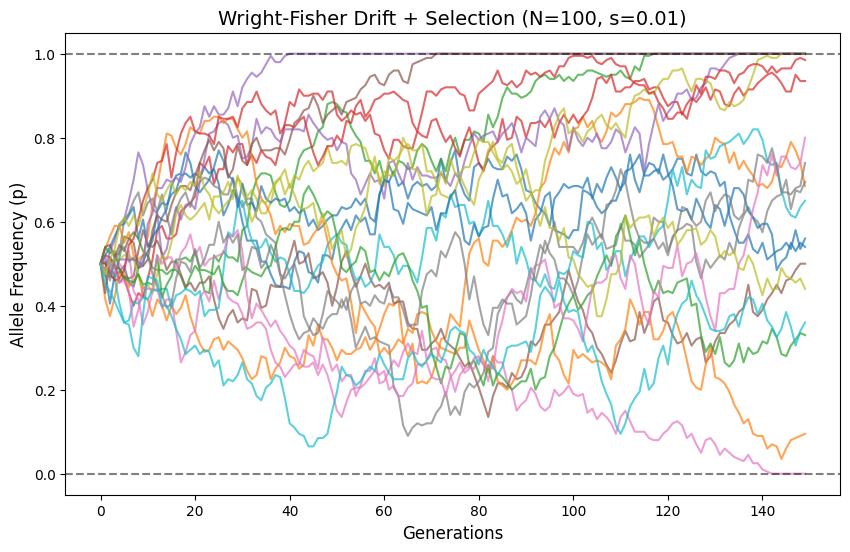

In [3]:
N = 100          # Population size
p0 = 0.5         # Starting frequency
generations = 150
replicates = 20

plt.figure(figsize=(10, 6))
for _ in range(replicates):
    traj = run_wright_fisher(N=N, p0=p0, generations=generations, s=0.01)
    plt.plot(traj, lw=1.5, alpha=0.7)

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.axhline(1, color='black', linestyle='--', alpha=0.5)
plt.title(f"Wright-Fisher Drift + Selection (N={N}, s=0.01)", fontsize=14)
plt.xlabel("Generations", fontsize=12)
plt.ylabel("Allele Frequency (p)", fontsize=12)
plt.ylim(-0.05, 1.05)
plt.show()

Step 3: Making it Interactive in Google Colab

In [4]:
import ipywidgets as widgets
from IPython.display import display

@widgets.interact(
    N=widgets.IntSlider(min=10, max=1000, step=10, value=100, description='Pop Size (N):'),
    s=widgets.FloatSlider(min=-0.1, max=0.1, step=0.005, value=0.0, description='Selection (s):'),
    p0=widgets.FloatSlider(min=0.05, max=0.95, step=0.05, value=0.5, description='Initial freq (p0):')
)
def interactive_wf(N, s, p0):
    plt.figure(figsize=(10, 5))
    for _ in range(15):
        traj = run_wright_fisher(N=N, p0=p0, generations=100, s=s)
        plt.plot(traj, lw=1.5, alpha=0.8)
    plt.axhline(0, color='gray', linestyle='--')
    plt.axhline(1, color='gray', linestyle='--')
    plt.title(f"Interactive Simulation: N={N}, s={s}, p0={p0}")
    plt.xlabel("Generations")
    plt.ylabel("Allele Frequency")
    plt.ylim(-0.05, 1.05)
    plt.show()

interactive(children=(IntSlider(value=100, description='Pop Size (N):', max=1000, min=10, step=10), FloatSlide…